Training images: 800
Testing images: 200


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/2
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 123ms/step - accuracy: 0.6516 - loss: 0.6427 - val_accuracy: 1.0000 - val_loss: 0.5195
Epoch 2/2
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - accuracy: 0.9516 - loss: 0.4086 - val_accuracy: 1.0000 - val_loss: 0.2204

FINAL RESULTS
Test Loss     : 0.2085
Test Accuracy : 100.0 %

CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Cat       1.00      1.00      1.00       112
         Dog       1.00      1.00      1.00        88

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200


CONFUSION MATRIX
[[112   0]
 [  0  88]]


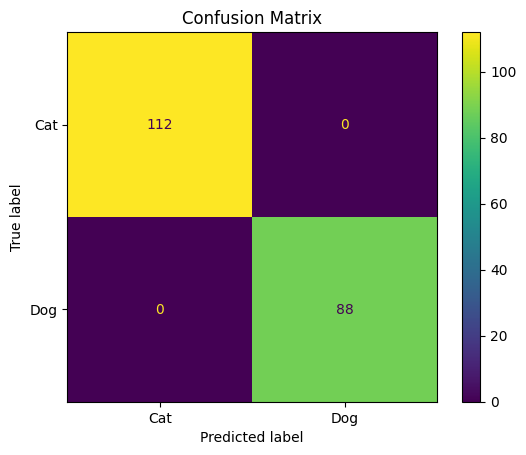


ROC - AUC
AUC Score: 1.0


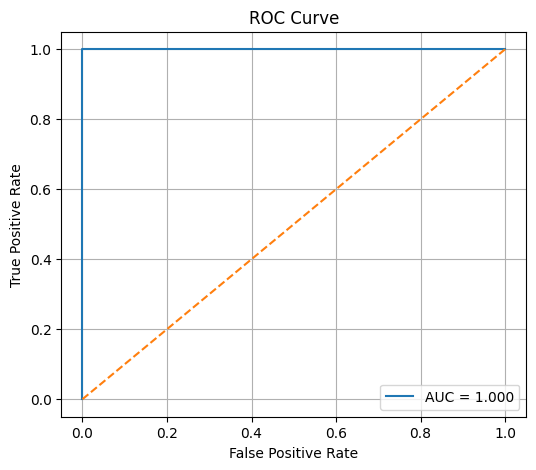

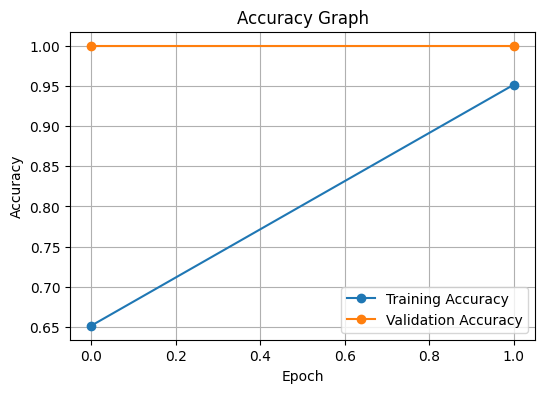

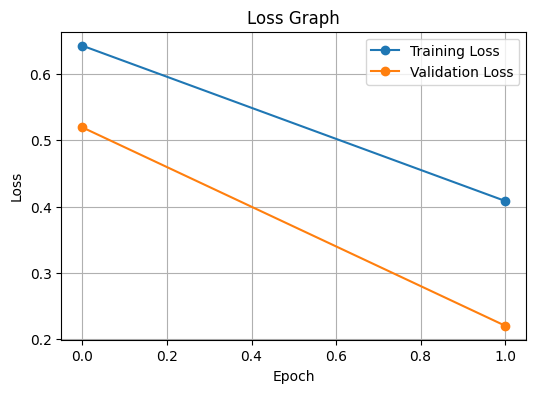


CNN COMPLETE


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense,
    Dropout, RandomFlip, Rescaling
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# =========================================================
# 1. PARAMETERS
# =========================================================

IMG_SIZE = 32
TRAIN_SIZE = 800
TEST_SIZE = 200
EPOCHS = 2
BATCH_SIZE = 64
LEARNING_RATE = 0.001

# =========================================================
# 2. CREATE SMALL IMAGE DATASET
#    0 = Cat
#    1 = Dog
# =========================================================

np.random.seed(42)

X = np.random.rand(
    TRAIN_SIZE + TEST_SIZE,
    IMG_SIZE,
    IMG_SIZE,
    3
).astype("float32")

y = np.zeros(TRAIN_SIZE + TEST_SIZE, dtype="float32")

# Create simple visual patterns for two classes
# Class 0: vertical pattern
# Class 1: horizontal pattern

for i in range(len(X)):

    if i % 2 == 0:
        y[i] = 0
        X[i, :, 14:18, :] += 0.5
    else:
        y[i] = 1
        X[i, 14:18, :, :] += 0.5

X = np.clip(X, 0, 1)

# Shuffle
indices = np.random.permutation(len(X))
X = X[indices]
y = y[indices]

# Split
x_train = X[:TRAIN_SIZE]
y_train = y[:TRAIN_SIZE]

x_test = X[TRAIN_SIZE:]
y_test = y[TRAIN_SIZE:]

print("Training images:", len(x_train))
print("Testing images:", len(x_test))

# =========================================================
# 3. DATA AUGMENTATION
# =========================================================

augmentation = Sequential([
    RandomFlip("horizontal")
])

# =========================================================
# 4. CNN MODEL
# =========================================================

model = Sequential([

    augmentation,

    Rescaling(1.0 / 1.0),

    Conv2D(16, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(64, activation="relu"),

    # DROPOUT
    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

# =========================================================
# 5. COMPILE
# =========================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# =========================================================
# 6. TRAIN
# =========================================================

history = model.fit(
    x_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    verbose=1
)

# =========================================================
# 7. ACCURACY AND LOSS
# =========================================================

loss, accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("\n==============================")
print("FINAL RESULTS")
print("==============================")

print("Test Loss     :", round(loss, 4))
print("Test Accuracy :", round(accuracy * 100, 2), "%")

# =========================================================
# 8. PREDICTIONS
# =========================================================

probability = model.predict(
    x_test,
    verbose=0
).ravel()

prediction = (probability >= 0.5).astype(int)

# =========================================================
# 9. CLASSIFICATION REPORT
# =========================================================

print("\n==============================")
print("CLASSIFICATION REPORT")
print("==============================")

print(
    classification_report(
        y_test,
        prediction,
        target_names=["Cat", "Dog"],
        zero_division=0
    )
)

# =========================================================
# 10. CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_test,
    prediction
)

print("\n==============================")
print("CONFUSION MATRIX")
print("==============================")

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

disp.plot()

plt.title("Confusion Matrix")
plt.show()

# =========================================================
# 11. ROC + AUC
# =========================================================

auc = roc_auc_score(
    y_test,
    probability
)

fpr, tpr, _ = roc_curve(
    y_test,
    probability
)

print("\n==============================")
print("ROC - AUC")
print("==============================")

print("AUC Score:", round(auc, 4))

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.grid()
plt.show()

# =========================================================
# 12. ACCURACY GRAPH
# =========================================================

plt.figure(figsize=(6, 4))

plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy Graph")

plt.legend()
plt.grid()
plt.show()

# =========================================================
# 13. LOSS GRAPH
# =========================================================

plt.figure(figsize=(6, 4))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Graph")

plt.legend()
plt.grid()
plt.show()

print("\n==============================")
print("CNN COMPLETE")
print("==============================")